<a href="https://colab.research.google.com/github/itmepavan/Deep-Learning-week-1/blob/main/deep_learning_week4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install tensorflow gradio scikit-learn seaborn

In [3]:
import os
import hashlib
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import gradio as gr

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models

In [8]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("/content/")

# The zip file extracts to '/content/trashnet-dataset-main'
# Let's dynamically find the folder containing our categories
base_extracted = "/content/trashnet-dataset-main"
if os.path.exists(base_extracted):
    # If the subfolders are deeper (e.g., in a 'data' or 'dataset-original' folder), locate them
    possible_sub = os.path.join(base_extracted, "dataset-original")
    if os.path.exists(possible_sub):
        DATA_DIR = possible_sub
    else:
        DATA_DIR = base_extracted
else:
    # Fallback to general content folder if structure is flat
    DATA_DIR = "/content/"

print("Dataset loaded successfully!")
print("DATA_DIR is set to:", DATA_DIR)
print("Contents of DATA_DIR:", os.listdir(DATA_DIR))

Saving trashnet-dataset-main.zip to trashnet-dataset-main (1).zip
Dataset loaded successfully!
DATA_DIR is set to: /content/trashnet-dataset-main
Contents of DATA_DIR: ['.gitignore', 'paper', 'plastic', 'metal', 'cardboard', 'README.md', 'glass', 'trash']


In [13]:
import hashlib
import os

classes = ["paper", "plastic", "glass", "metal", "cardboard"]
unique_images = []
hashes = set()

for category in classes:
    folder = os.path.join(DATA_DIR, category)
    if not os.path.exists(folder):
        continue

    for file in os.listdir(folder):
        path = os.path.join(folder, file)

        if not os.path.isfile(path):
            continue

        try:
            with open(path, "rb") as f:
                image_hash = hashlib.sha256(f.read()).hexdigest()

            if image_hash not in hashes:
                hashes.add(image_hash)
                # Store capitalized category names for clean display labels later
                unique_images.append((path, category.capitalize()))

        except Exception:
            pass

print("Unique images:", len(unique_images))

Unique images: 2387


In [10]:
train_data, temp_data = train_test_split(
    unique_images,
    test_size=0.30,
    stratify=[x[1] for x in unique_images],
    random_state=42
)

val_data, test_data = train_test_split(
    temp_data,
    test_size=0.50,
    stratify=[x[1] for x in temp_data],
    random_state=42
)

splits = {
    "train": train_data,
    "validation": val_data,
    "test": test_data
}

for split, data in splits.items():
    for path, category in data:
        destination = f"/content/{split}/{category}"
        os.makedirs(destination, exist_ok=True)
        shutil.copy2(path, destination)

print("Dataset split completed!")

Dataset split completed!


In [11]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print(class_names)

Found 1670 files belonging to 5 classes.
Found 358 files belonging to 5 classes.
Found 359 files belonging to 5 classes.
['Cardboard', 'Glass', 'Metal', 'Paper', 'Plastic']


In [12]:
baseline = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(5, activation='softmax')
])

baseline.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history1 = baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 47s 864ms/step - accuracy: 0.3419 - loss: 1.7892 - val_accuracy: 0.4888 - val_loss: 1.2429
Epoch 2/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 80s 829ms/step - accuracy: 0.5126 - loss: 1.1569 - val_accuracy: 0.5503 - val_loss: 1.1359
Epoch 3/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 82s 829ms/step - accuracy: 0.6281 - loss: 0.9755 - val_accuracy: 0.5615 - val_loss: 1.0893
Epoch 4/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 82s 828ms/step - accuracy: 0.7042 - loss: 0.7952 - val_accuracy: 0.6145 - val_loss: 1.1708
Epoch 5/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 81s 812ms/step - accuracy: 0.7928 - loss: 0.6082 - val_accuracy: 0.6089 - val_loss: 1.1230


In [14]:
improved = models.Sequential([
    layers.Input(shape=(128,128,3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(5, activation='softmax')
])

improved.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = improved.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

improved.save("waste_model.keras")

print("Improved model saved!")

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.2455 - loss: 1.5943 - val_accuracy: 0.2933 - val_loss: 1.5456
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.3222 - loss: 1.4982 - val_accuracy: 0.4050 - val_loss: 1.4023
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.4042 - loss: 1.3900 - val_accuracy: 0.4134 - val_loss: 1.3468
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.4509 - loss: 1.3015 - val_accuracy: 0.5279 - val_loss: 1.2375
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 80s 1s/step - accuracy: 0.4784 - loss: 1.2371 - val_accuracy: 0.4804 - val_loss: 1.2511
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.5042 - loss: 1.1901 - val_accuracy: 0.5894 - val_loss: 1.1284
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.5293 - loss: 1.1634 - val_accuracy: 0.6117 - val_loss: 1.0906
Epoch 8/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.5371 - loss: 1.1548 - val_accuracy: 0.5726 - val_loss:

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 188ms/step - accuracy: 0.6240 - loss: 1.0631
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 303ms/step - accuracy: 0.5850 - loss: 1.1408
Baseline Accuracy: 62.39554286003113
Improved Accuracy: 58.49581956863403


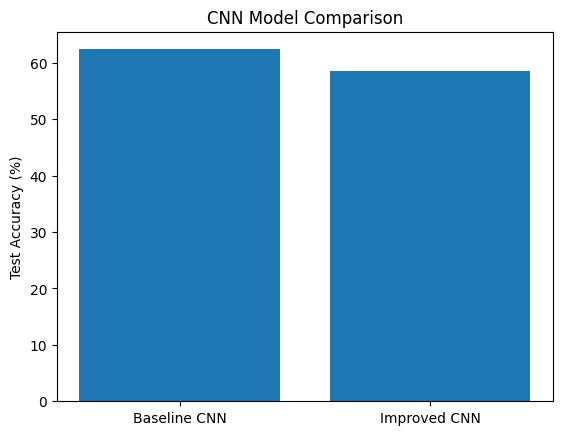

In [15]:
base_loss, base_acc = baseline.evaluate(test_ds)
new_loss, new_acc = improved.evaluate(test_ds)

print("Baseline Accuracy:", base_acc * 100)
print("Improved Accuracy:", new_acc * 100)

plt.bar(
    ["Baseline CNN", "Improved CNN"],
    [base_acc * 100, new_acc * 100]
)

plt.ylabel("Test Accuracy (%)")
plt.title("CNN Model Comparison")
plt.show()

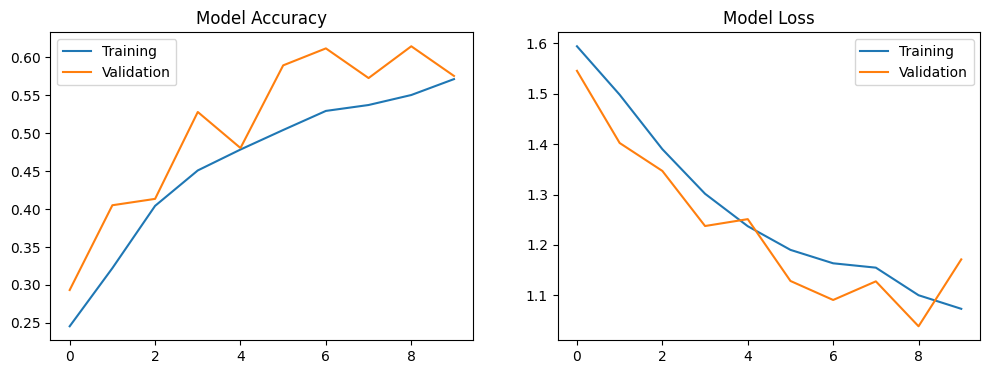

In [16]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history2.history['accuracy'], label='Training')
plt.plot(history2.history['val_accuracy'], label='Validation')
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history2.history['loss'], label='Training')
plt.plot(history2.history['val_loss'], label='Validation')
plt.title("Model Loss")
plt.legend()

plt.show()

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step
              precision    recall  f1-score   support

   Cardboard       0.91      0.67      0.77        60
       Glass       0.62      0.52      0.57        75
       Metal       0.47      0.39      0.42        62
       Paper       0.48      0.91      0.63        89
     Plastic       0.79      0.36      0.49        73

    accuracy                           0.58       359
   macro avg       0.65      0.57      0.58       359
weighted avg       0.64      0.58      0.58       359



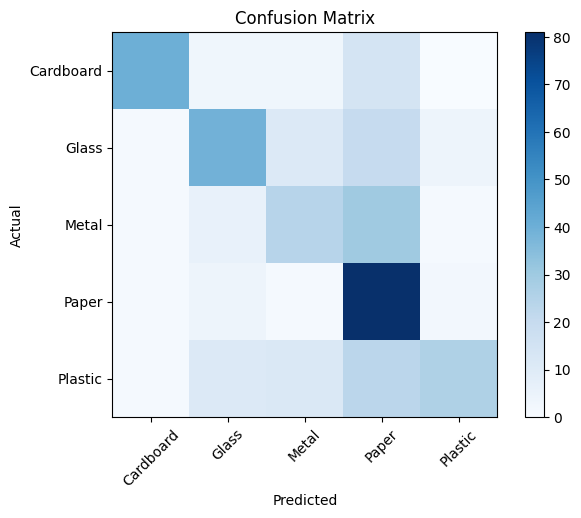

In [17]:
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

predictions = improved.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7,5))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(5), class_names, rotation=45)
plt.yticks(range(5), class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.colorbar()
plt.show()

In [18]:
from PIL import Image

def predict_waste(image):
    image = image.convert("RGB")
    image = image.resize((128,128))

    image = np.array(image)
    image = np.expand_dims(image, axis=0)

    prediction = improved.predict(image, verbose=0)[0]

    result = {
        class_names[i]: float(prediction[i])
        for i in range(len(class_names))
    }

    return result

In [19]:
demo = gr.Interface(
    fn=predict_waste,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=5),
    title="Waste Image Classification System",
    description="Upload a waste image to identify its category."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6645e7924769139473.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
